Using device: cuda
Starting Attention U-Net GAN Training...

Epoch [1/20] | D Loss: 0.5751 | G Total Loss: 13.9478 | G L1 Loss: 0.1284
Epoch [2/20] | D Loss: 0.4858 | G Total Loss: 14.2389 | G L1 Loss: 0.1285
Epoch [3/20] | D Loss: 0.5265 | G Total Loss: 13.8581 | G L1 Loss: 0.1249
Epoch [4/20] | D Loss: 0.5226 | G Total Loss: 13.7443 | G L1 Loss: 0.1242
Epoch [5/20] | D Loss: 0.5367 | G Total Loss: 13.4653 | G L1 Loss: 0.1222
Epoch [6/20] | D Loss: 0.5348 | G Total Loss: 12.7214 | G L1 Loss: 0.1151
Epoch [7/20] | D Loss: 0.5472 | G Total Loss: 12.6099 | G L1 Loss: 0.1141
Epoch [8/20] | D Loss: 0.5093 | G Total Loss: 12.5195 | G L1 Loss: 0.1128
Epoch [9/20] | D Loss: 0.5460 | G Total Loss: 12.4715 | G L1 Loss: 0.1126
Epoch [10/20] | D Loss: 0.5325 | G Total Loss: 12.4946 | G L1 Loss: 0.1129
Epoch [11/20] | D Loss: 0.5315 | G Total Loss: 12.2936 | G L1 Loss: 0.1111
Epoch [12/20] | D Loss: 0.5376 | G Total Loss: 12.1718 | G L1 Loss: 0.1097
Epoch [13/20] | D Loss: 0.5352 | G Total Loss: 1

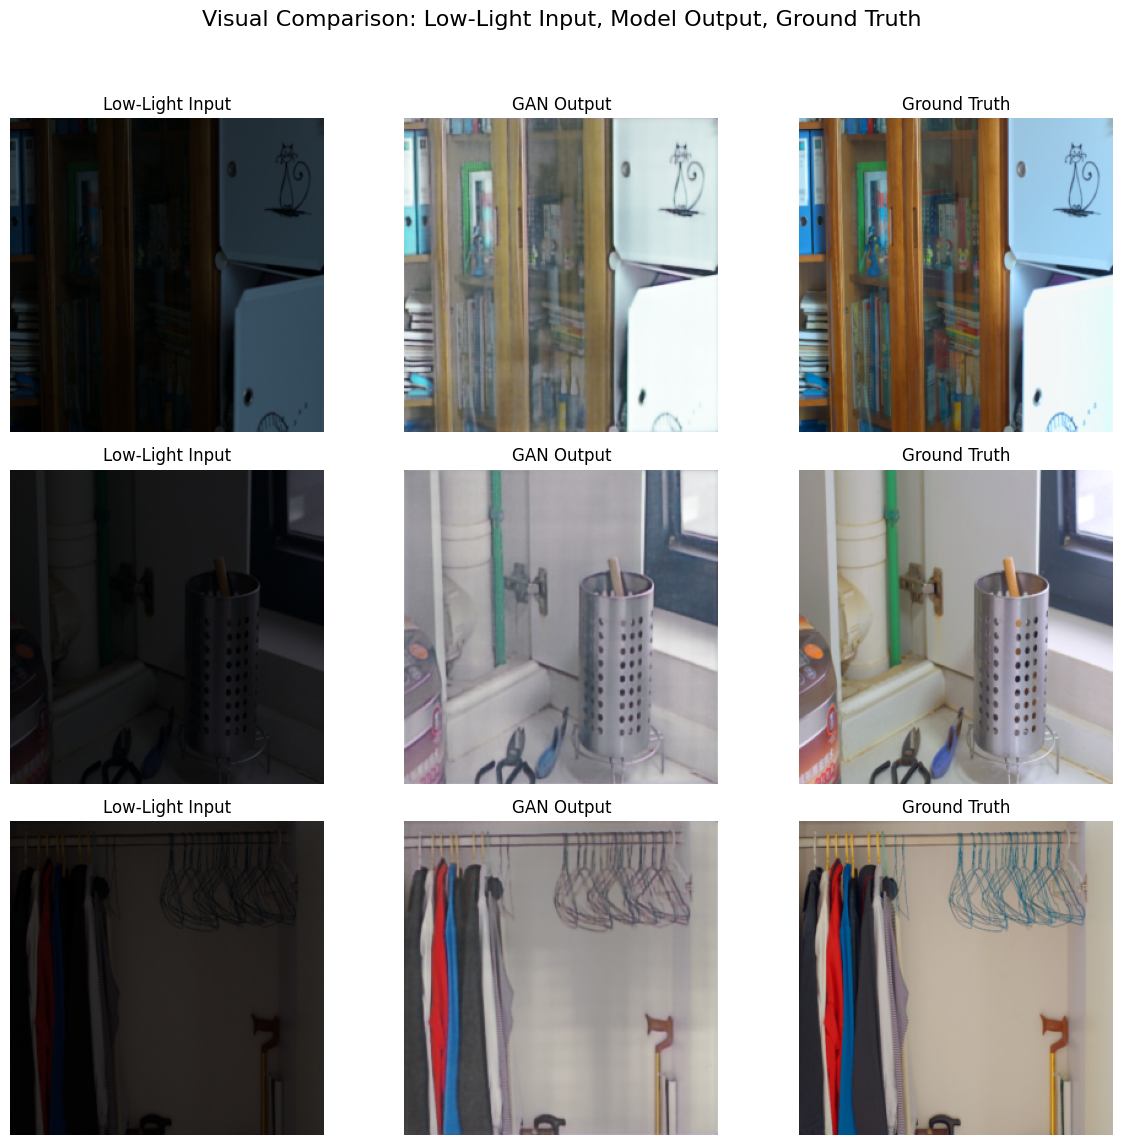

In [6]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms.functional import to_pil_image

# 0. REPRODUCIBILITY

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# 1. CUSTOM LOL DATASET LOADER

class LOLDataset(Dataset):
    def __init__(self, root_dir, mode="train", transform=None):
        """
        Custom dataset for the LOL (Low-Light) Dataset.
        Expects the extracted folder structure:
        - root_dir/our485/low (Train Dark)
        - root_dir/our485/high (Train Bright)
        - root_dir/eval15/low (Test Dark)
        - root_dir/eval15/high (Test Bright)
        """
        self.mode = mode
        self.transform = transform

        folder = "our485" if mode == "train" else "eval15"
        self.low_dir = os.path.join(root_dir, folder, 'low')
        self.high_dir = os.path.join(root_dir, folder, 'high')

        self.image_filenames = sorted(os.listdir(self.low_dir))

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        img_name = self.image_filenames[idx]

        low_img_path = os.path.join(self.low_dir, img_name)
        high_img_path = os.path.join(self.high_dir, img_name)

        low_image = Image.open(low_img_path).convert('RGB')
        high_image = Image.open(high_img_path).convert('RGB')

        if self.transform:
            low_image = self.transform(low_image)
            high_image = self.transform(high_image)

        return low_image, high_image

# 2. ATTENTION U-NET GENERATOR

class AttentionBlock(nn.Module):
    def __init__(self, in_channels_x, in_channels_g, inter_channels):
        super(AttentionBlock, self).__init__()
        self.W_g = nn.Conv2d(in_channels_g, inter_channels, kernel_size=1, stride=1, padding=0)
        self.W_x = nn.Conv2d(in_channels_x, inter_channels, kernel_size=1, stride=2, padding=0)
        self.psi = nn.Sequential(
            nn.Conv2d(inter_channels, 1, kernel_size=1, stride=1, padding=0),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)
        self.final_conv = nn.Conv2d(in_channels_x, in_channels_x, kernel_size=1, stride=1, padding=0)
        self.final_bn = nn.BatchNorm2d(in_channels_x)

    def forward(self, x, g):
        theta_x = self.W_x(x)
        phi_g = self.W_g(g)
        if theta_x.shape[2:] != phi_g.shape[2:]:
            theta_x = F.interpolate(theta_x, size=phi_g.shape[2:], mode='bilinear', align_corners=False)
        concat_xg = phi_g + theta_x
        act_xg = self.relu(concat_xg)
        sigmoid_xg = self.psi(act_xg)
        upsample_psi = F.interpolate(sigmoid_xg, size=x.shape[2:], mode='bilinear', align_corners=False)
        y = upsample_psi * x
        return self.final_bn(self.final_conv(y))


def double_conv(in_c, out_c):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True),
        nn.Dropout(0.2),
        nn.Conv2d(out_c, out_c, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True),
        nn.Dropout(0.2)
    )


class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        self.max_pool_2x2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # DOWN CONVOLUTION (ENCODER)
        self.down_conv_1 = double_conv(3, 64)
        self.down_conv_2 = double_conv(64, 128)
        self.down_conv_3 = double_conv(128, 256)
        self.down_conv_4 = double_conv(256, 512)
        self.down_conv_5 = double_conv(512, 1024)

        # ATTENTION GATES
        self.ag1 = AttentionBlock(in_channels_x=512, in_channels_g=1024, inter_channels=256)
        self.ag2 = AttentionBlock(in_channels_x=256, in_channels_g=512, inter_channels=128)
        self.ag3 = AttentionBlock(in_channels_x=128, in_channels_g=256, inter_channels=64)
        self.ag4 = AttentionBlock(in_channels_x=64, in_channels_g=128, inter_channels=32)

        # UP CONVOLUTION (DECODER)
        self.up_trans_1 = nn.ConvTranspose2d(in_channels=1024, out_channels=512, kernel_size=2, stride=2)
        self.up_conv_1 = double_conv(1024, 512)

        self.up_trans_2 = nn.ConvTranspose2d(in_channels=512, out_channels=256, kernel_size=2, stride=2)
        self.up_conv_2 = double_conv(512, 256)

        self.up_trans_3 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=2, stride=2)
        self.up_conv_3 = double_conv(256, 128)

        self.up_trans_4 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=2, stride=2)
        self.up_conv_4 = double_conv(128, 64)

        self.out = nn.Conv2d(in_channels=64, out_channels=3, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, image):
        # ENCODER
        x1 = self.down_conv_1(image)
        x2 = self.max_pool_2x2(x1)
        x3 = self.down_conv_2(x2)
        x4 = self.max_pool_2x2(x3)
        x5 = self.down_conv_3(x4)
        x6 = self.max_pool_2x2(x5)
        x7 = self.down_conv_4(x6)
        x8 = self.max_pool_2x2(x7)
        x9 = self.down_conv_5(x8)

        # DECODER WITH ATTENTION
        x7_att = self.ag1(x=x7, g=x9)
        x_up1 = self.up_trans_1(x9)
        x = self.up_conv_1(torch.cat([x_up1, x7_att], 1))

        x5_att = self.ag2(x=x5, g=x)
        x_up2 = self.up_trans_2(x)
        x = self.up_conv_2(torch.cat([x_up2, x5_att], 1))

        x3_att = self.ag3(x=x3, g=x)
        x_up3 = self.up_trans_3(x)
        x = self.up_conv_3(torch.cat([x_up3, x3_att], 1))

        x1_att = self.ag4(x=x1, g=x)
        x_up4 = self.up_trans_4(x)
        x = self.up_conv_4(torch.cat([x_up4, x1_att], 1))

        x = self.out(x)
        return self.sigmoid(x)

# 3. PATCHGAN DISCRIMINATOR (Conditional 70x70 PatchGAN)

class PatchDiscriminator(nn.Module):
    def __init__(self, in_channels=6):  # 3 channels (Low-light) + 3 channels (Target/Generated)
        super(PatchDiscriminator, self).__init__()

        def discriminator_block(in_f, out_f, stride=2, normalize=True):
            layers = [nn.Conv2d(in_f, out_f, kernel_size=4, stride=stride, padding=1, bias=not normalize)]
            if normalize:
                layers.append(nn.BatchNorm2d(out_f))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *discriminator_block(in_channels, 64, stride=2, normalize=False),
            *discriminator_block(64, 128, stride=2, normalize=True),
            *discriminator_block(128, 256, stride=2, normalize=True),
            *discriminator_block(256, 512, stride=1, normalize=True),
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1)  # Outputs patch prediction logits
        )

    def forward(self, img_low, img_high):
        # Concatenate condition (low-light) and target (enhanced/normal) along channel dimension
        x = torch.cat([img_low, img_high], dim=1)
        return self.model(x)

# 4. SETUP & DATALOADERS

LEARNING_RATE = 0.0002
BATCH_SIZE = 4
EPOCHS = 20
LAMBDA_L1 = 100.0  # Weight for Generator L1 Loss

ROOT_DIR = "/content/drive/MyDrive/archive/lol_dataset"
CHECKPOINT_DIR = "/content/drive/MyDrive/archive/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

train_dataset = LOLDataset(root_dir=ROOT_DIR, mode="train", transform=img_transform)
test_dataset = LOLDataset(root_dir=ROOT_DIR, mode="eval", transform=img_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

# 5. MODEL INITIALIZATION, LOSSES, AND OPTIMIZERS

generator = UNet().to(device)
discriminator = PatchDiscriminator(in_channels=6).to(device)

# Loss Functions
criterion_GAN = nn.BCEWithLogitsLoss()
criterion_L1 = nn.L1Loss()

# Optimizers (no weight decay -- atypical/unnecessary for GAN training)
optimizer_G = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))

# 6. GAN TRAINING LOOP

print("Starting Attention U-Net GAN Training...\n")

for epoch in range(EPOCHS):
    generator.train()
    discriminator.train()

    total_d_loss = 0.0
    total_g_loss = 0.0
    total_l1_loss = 0.0

    for batch_low, batch_high in train_loader:
        batch_low = batch_low.to(device)
        batch_high = batch_high.to(device)


        #  Train Discriminator: max log(D(x, y)) + log(1 - D(x, G(x)))

        optimizer_D.zero_grad()

        # Generate Fake Normal-Light Images using Attention U-Net
        fake_high = generator(batch_low)

        # Real Loss
        pred_real = discriminator(batch_low, batch_high)
        target_real = torch.ones_like(pred_real, device=device)
        loss_D_real = criterion_GAN(pred_real, target_real)

        # Fake Loss (detach fake_high so Generator gradients are not computed)
        pred_fake = discriminator(batch_low, fake_high.detach())
        target_fake = torch.zeros_like(pred_fake, device=device)
        loss_D_fake = criterion_GAN(pred_fake, target_fake)

        # Total Discriminator Loss
        loss_D = (loss_D_real + loss_D_fake) * 0.5
        loss_D.backward()
        optimizer_D.step()

        # -------------------------------------------------------------
        #  Train Generator: max log(D(x, G(x))) + LAMBDA_L1 * |y - G(x)|
        # -------------------------------------------------------------
        optimizer_G.zero_grad()

        # 1. Adversarial Loss (fool discriminator)
        pred_fake_g = discriminator(batch_low, fake_high)
        loss_G_GAN = criterion_GAN(pred_fake_g, target_real)

        # 2. Content / L1 Reconstruction Loss (pixel-to-pixel match)
        loss_G_L1 = criterion_L1(fake_high, batch_high)

        # Total Generator Loss
        loss_G = loss_G_GAN + (LAMBDA_L1 * loss_G_L1)
        loss_G.backward()
        optimizer_G.step()

        total_d_loss += loss_D.item()
        total_g_loss += loss_G.item()
        total_l1_loss += loss_G_L1.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)
    avg_l1_loss = total_l1_loss / len(train_loader)

    print(f"Epoch [{epoch + 1}/{EPOCHS}] | D Loss: {avg_d_loss:.4f} | G Total Loss: {avg_g_loss:.4f} | G L1 Loss: {avg_l1_loss:.4f}")

    # Checkpoint after every epoch
    torch.save(generator.state_dict(), os.path.join(CHECKPOINT_DIR, f"generator_epoch{epoch + 1}.pth"))
    torch.save(discriminator.state_dict(), os.path.join(CHECKPOINT_DIR, f"discriminator_epoch{epoch + 1}.pth"))

# Save final models under fixed names too, for easy reloading
torch.save(generator.state_dict(), os.path.join(CHECKPOINT_DIR, "generator_final.pth"))
torch.save(discriminator.state_dict(), os.path.join(CHECKPOINT_DIR, "discriminator_final.pth"))


# 7. TESTING & VISUAL COMPARISON (single combined pass)

print("\nEvaluating on Test Set...")
generator.eval()

total_test_loss = 0.0

num_display_images = 3
display_low, display_out, display_high = [], [], []

with torch.no_grad():
    for batch_low, batch_high in test_loader:
        batch_low_dev = batch_low.to(device)
        batch_high_dev = batch_high.to(device)

        outputs = generator(batch_low_dev)

        # L1 loss
        loss = criterion_L1(outputs, batch_high_dev)
        total_test_loss += loss.item()

        # Collect a few images for visualization
        outputs_cpu = outputs.cpu()
        if len(display_low) < num_display_images:
            needed = num_display_images - len(display_low)
            display_low.extend(batch_low[:needed])
            display_out.extend(outputs_cpu[:needed])
            display_high.extend(batch_high[:needed])

avg_test_loss = total_test_loss / len(test_loader)

print("\n====================================")
print(f"Final Test Loss (L1 Error): {avg_test_loss:.4f}")
print("====================================")


# 8. VISUAL COMPARISON

fig, axes = plt.subplots(num_display_images, 3, figsize=(12, 4 * num_display_images))
fig.suptitle('Visual Comparison: Low-Light Input, Model Output, Ground Truth', fontsize=16)

for i in range(num_display_images):
    low_pil = to_pil_image(display_low[i])
    output_pil = to_pil_image(display_out[i])
    high_pil = to_pil_image(display_high[i])

    axes[i, 0].imshow(low_pil)
    axes[i, 0].set_title('Low-Light Input')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(output_pil)
    axes[i, 1].set_title('GAN Output')
    axes[i, 1].axis('off')

    axes[i, 2].imshow(high_pil)
    axes[i, 2].set_title('Ground Truth')
    axes[i, 2].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [1]:
%%capture
!pip install lpips torch-fidelity
!pip install lpips torchmetrics[image] torch-fidelity

## 9. LPIPS and FID Evaluation

In [7]:
import os
import torch
import lpips
from torchmetrics.image.fid import FrechetInceptionDistance
from torch.utils.data import DataLoader
from torchvision import transforms

# 1. Ensure Device & Model Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = UNet().to(device)

# Load saved weights if model isn't currently in memory
checkpoint_path = "/content/drive/MyDrive/archive/checkpoints/generator_final.pth"
if os.path.exists(checkpoint_path):
    generator.load_state_dict(torch.load(checkpoint_path, map_location=device))
generator.eval()

# Ensure test_loader is available
if 'test_loader' not in globals():
    img_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor()
    ])
    test_dataset = LOLDataset(root_dir="/content/drive/MyDrive/archive/lol_dataset", mode="eval", transform=img_transform)
    test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, pin_memory=True)

# 2. Initialize Evaluation Metrics
lpips_model = lpips.LPIPS(net='alex').to(device)
fid = FrechetInceptionDistance(feature=64).to(device)

print("Calculating LPIPS and FID...")

total_lpips_score = 0.0
num_test_samples = 0

real_images_fid = []
fake_images_fid = []

with torch.no_grad():
    for batch_low, batch_high in test_loader:
        batch_low = batch_low.to(device)
        batch_high = batch_high.to(device)

        generated_high = generator(batch_low)

        # LPIPS calculation (normalize range [0, 1] to [-1, 1])
        norm_generated = generated_high * 2 - 1
        norm_real = batch_high * 2 - 1

        lpips_score = lpips_model(norm_generated, norm_real).mean()
        total_lpips_score += lpips_score.item() * batch_low.size(0)
        num_test_samples += batch_low.size(0)

        # Collect batches for FID calculation
        real_images_fid.append(batch_high)
        fake_images_fid.append(generated_high)

    # Convert [0, 1] float tensors to uint8 [0, 255] tensors for FID
    real_concat = (torch.cat(real_images_fid) * 255).to(torch.uint8)
    fake_concat = (torch.cat(fake_images_fid) * 255).to(torch.uint8)

    # Update and compute FID score
    fid.update(real_concat, real=True)
    fid.update(fake_concat, real=False)
    fid_score = fid.compute()

avg_lpips_score = total_lpips_score / num_test_samples

print(f"\nAverage LPIPS Score: {avg_lpips_score:.4f}")
print(f"FID Score: {fid_score.item():.4f}")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth
Calculating LPIPS and FID...

Average LPIPS Score: 0.2157
FID Score: 2.4558
